# 02 · Imbalance Handling Benchmark (S5)

**Course:** Data Mining (DA) — Autumn 2026 · **Group 7**  
**Topic:** Credit Card Fraud Detection (Option E)

**Bước S5 — PHASE CỐT LÕI của project.**

## Mục tiêu

Chạy **ma trận đầy đủ 5 model × 5 kỹ thuật imbalance × 3 mức sampling** để trả lời:

| Câu hỏi | Cách trả lời |
|---|---|
| KD #1: Model nào F1 cao nhất? | Bảng xếp hạng F1 / AUC-PR |
| KD #2: Recall tại precision ≥ 95%? | `find_threshold` cho mọi tổ hợp |
| KD #7: Kỹ thuật imbalance ảnh hưởng chi phí thế nào? | Cột cost + #flag |

## Quy trình đánh giá (BẮT BUỘC)

```
1. GridSearchCV trên TẬP TRAIN  (scoring = average_precision)
2. Refit trên toàn bộ train với hyperparameter tốt nhất
3. Đánh giá MỘT LẦN trên test  → chỉ con số ở bước này được báo cáo
```

> ⚠️ **Không tune trên test.** Xem F3 trong `FINDINGS.md` — có ví dụ cụ thể
> cho thấy chọn theo test sẽ ra quyết định sai.

## Kỹ thuật lưu kết quả tăng dần (checkpoint)

Benchmark chạy 1.5–3 giờ. Mỗi tổ hợp xong sẽ **append ngay** vào CSV, nên nếu
kernel chết giữa chừng, chạy lại sẽ **bỏ qua tổ hợp đã có** (resume).

In [1]:
import sys, warnings, time, json
warnings.filterwarnings("ignore")

from pathlib import Path
PROJECT_ROOT = Path(r"e:\Projects\DataMining")
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (SEED, PALETTE, TABLES, CHARTS, MODELS, MIN_PRECISION,
                        COST_PER_FN, COST_PER_FP)
from src.modeling import (make_pipeline, MODEL_LABELS, IMBALANCE_LABELS,
                          allowed_imbalances, cv_evaluate)
from src.evaluation import find_threshold, evaluate, confusion_counts

from sklearn.model_selection import GridSearchCV, StratifiedKFold

sns.set_style("whitegrid")
plt.rcParams.update({"figure.figsize": (14, 6), "font.family": "DejaVu Sans"})

BENCH_CSV = TABLES / "imbalance_benchmark.csv"
PRED_DIR = MODELS / "s5_predictions"
PRED_DIR.mkdir(parents=True, exist_ok=True)

print("BENCH_CSV  :", BENCH_CSV)
print("PRED_DIR   :", PRED_DIR)
print("exists     :", BENCH_CSV.exists())

BENCH_CSV  : E:\Projects\DataMining\artifacts\tables\imbalance_benchmark.csv
PRED_DIR   : E:\Projects\DataMining\artifacts\models\s5_predictions
exists     : True


In [2]:
d = joblib.load(MODELS / "split_with_features.joblib")
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
COLS = list(X_train.columns)

print("train:", X_train.shape, "| test:", X_test.shape)
print("fraud train:", int(y_train.sum()), "| fraud test:", int(y_test.sum()))
print("features:", len(COLS))

train: (198608, 35) | test: (85118, 35)
fraud train: 331 | fraud test: 142
features: 35


## 1. Thiết kế ma trận thí nghiệm

| Model | Resampling techniques | Sampling strategy |
|---|---|---|
| Logistic Regression | none, undersample, smote, smoteenn, class_weight | — |
| Decision Tree | none, undersample, smote, smoteenn, class_weight | — |
| Random Forest | none, undersample, smote, smoteenn, class_weight | — |
| XGBoost | none, undersample, smote, smoteenn, class_weight | — |
| Isolation Forest | none (unsupervised) | — |

**Cộng thêm:** SMOTE với 4 mức sampling (0.01, 0.05, 0.1, 0.5) trên RandomForest
và XGBoost để có **đường cong trade-off** đầy đủ giữa mức cân bằng và hiệu năng.

→ Tổng: **~27 tổ hợp chính** + GridSearchCV bên trong mỗi tổ hợp.

In [3]:
# Grid hyperparameter cho từng model — giữ NHỎ để tổng thời gian < 3 giờ
GRIDS = {
    "logreg": {
        "clf__C": [0.01, 0.1, 1.0],
    },
    "dtree": {
        "clf__max_depth": [5, 10, None],
        "clf__min_samples_leaf": [1, 50],
    },
    "rf": {
        "clf__max_depth": [10, None],
        "clf__min_samples_leaf": [1, 10],
    },
    "xgb": {
        "clf__max_depth": [4, 6],
        "clf__learning_rate": [0.1],
        "clf__n_estimators": [200, 400],
    },
}

# SMOTE sampling_strategy sweep
SMOTE_SWEEP = [0.01, 0.05, 0.1, 0.5]

# Ma tran chinh: (model, imbalance, strategy)
BASE_MATRIX = []
for m in ["logreg", "dtree", "rf", "xgb"]:
    for imb in ["none", "undersample", "smote", "smoteenn", "class_weight"]:
        strat = 0.1 if imb in ("smote", "smoteenn") else None
        BASE_MATRIX.append((m, imb, strat))
BASE_MATRIX.append(("iforest", "none", None))

# Sweep sampling_strategy cho SMOTE tren 2 model manh nhat
SWEEP_MATRIX = []
for m in ["rf", "xgb"]:
    for s in SMOTE_SWEEP:
        SWEEP_MATRIX.append((m, "smote", s))

print("Base matrix :", len(BASE_MATRIX), "combinations")
print("Sweep matrix:", len(SWEEP_MATRIX), "combinations")
print("TOTAL       :", len(BASE_MATRIX) + len(SWEEP_MATRIX))

for m, imb, s in BASE_MATRIX + SWEEP_MATRIX:
    print(f"  {m:8s} | {imb:13s} | strategy={s}")

Base matrix : 21 combinations
Sweep matrix: 8 combinations
TOTAL       : 29
  logreg   | none          | strategy=None
  logreg   | undersample   | strategy=None
  logreg   | smote         | strategy=0.1
  logreg   | smoteenn      | strategy=0.1
  logreg   | class_weight  | strategy=None
  dtree    | none          | strategy=None
  dtree    | undersample   | strategy=None
  dtree    | smote         | strategy=0.1
  dtree    | smoteenn      | strategy=0.1
  dtree    | class_weight  | strategy=None
  rf       | none          | strategy=None
  rf       | undersample   | strategy=None
  rf       | smote         | strategy=0.1
  rf       | smoteenn      | strategy=0.1
  rf       | class_weight  | strategy=None
  xgb      | none          | strategy=None
  xgb      | undersample   | strategy=None
  xgb      | smote         | strategy=0.1
  xgb      | smoteenn      | strategy=0.1
  xgb      | class_weight  | strategy=None
  iforest  | none          | strategy=None
  rf       | smote         | 

## 2. Hàm chạy một tổ hợp (có checkpoint)

* GridSearchCV trên **train** với `scoring="average_precision"` (AUC-PR)
* Refit trên toàn train
* Đánh giá **một lần** trên test
* Lưu prediction (`y_score`) ra file `.npy` để bước S7/S8/S9 dùng lại —
  không phải train lại!
* Append kết quả vào CSV ngay lập tức

In [4]:
def combo_key(model, imbalance, strategy):
    return f"{model}__{imbalance}__{strategy if strategy is not None else 'na'}"


def run_one(model, imbalance, strategy, n_jobs=-1, verbose=False):
    """Chay 1 to hop: GridSearchCV tren train -> refit -> danh gia 1 lan tren test."""
    key = combo_key(model, imbalance, strategy)
    t0 = time.time()

    # --- Isolation Forest: xu ly rieng (khong co predict_proba) ---
    if model == "iforest":
        from src.modeling import fit_isolation_forest

        res, iso, pre = fit_isolation_forest(
            X_train, y_train, X_test, y_test,
            scaler="standard", feature_cols=COLS,
        )
        y_score = res["y_score"]
        y_pred = res["y_pred"]
        best_params = {"contamination": 0.001672, "n_estimators": 300}
        grid_best_cv = np.nan
        pipe = None
    else:
        pipe = make_pipeline(
            model, imbalance=imbalance, sampler_strategy=strategy,
            scaler="standard", feature_cols=COLS,
        )
        grid = GRIDS.get(model, {})
        skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

        if grid:
            # n_jobs=1 cho imblearn pipeline (tranh treo multiprocessing tren Win)
            gs = GridSearchCV(
                pipe, grid, cv=skf, scoring="average_precision",
                n_jobs=1, refit=True, verbose=0,
            )
            gs.fit(X_train, y_train)
            pipe = gs.best_estimator_
            best_params = gs.best_params_
            grid_best_cv = float(gs.best_score_)
        else:
            pipe.fit(X_train, y_train)
            best_params = {}
            grid_best_cv = np.nan

        y_score = pipe.predict_proba(X_test)[:, 1]
        y_pred = (y_score >= 0.5).astype(int)

    # --- Metric tai threshold mac dinh ---
    met = evaluate(y_test, y_pred, y_score)

    # --- Threshold tot nhat tai precision >= 95% ---
    thr_info = find_threshold(y_test, y_score, MIN_PRECISION)

    # --- Chi phi tai threshold 0.5 ---
    cc = confusion_counts(y_test, y_pred)
    cost = cc["fn"] * COST_PER_FN + cc["fp"] * COST_PER_FP

    row = {
        "model": model,
        "model_label": MODEL_LABELS[model],
        "imbalance": imbalance,
        "imbalance_label": IMBALANCE_LABELS[imbalance],
        "strategy": strategy,
        "key": key,
        "grid_best_cv_ap": grid_best_cv,
        "best_params": json.dumps(best_params, default=str),
        "precision": met["precision"],
        "recall": met["recall"],
        "f1": met["f1"],
        "accuracy": met["accuracy"],
        "auc_roc": met["auc_roc"],
        "auc_pr": met["auc_pr"],
        "n_pred_pos": met["n_pred_pos"],
        "tp": cc["tp"], "fp": cc["fp"], "fn": cc["fn"], "tn": cc["tn"],
        "cost_at_0.5": cost,
        "thr_p95": thr_info["threshold"] if thr_info else np.nan,
        "precision_p95": thr_info["precision"] if thr_info else np.nan,
        "recall_p95": thr_info["recall"] if thr_info else np.nan,
        "f1_p95": thr_info["f1"] if thr_info else np.nan,
        "seconds": round(time.time() - t0, 1),
    }

    # Luu y_score + threshold de buoc sau dung lai
    np.save(PRED_DIR / f"{key}.npy", y_score)

    # Luu model (chi khi la model khong resample hoac best)
    if pipe is not None:
        joblib.dump(pipe, MODELS / f"s5_{key}.joblib")

    return row

## 3. ⭐ Chạy toàn bộ benchmark (có resume)

Cell dưới đây chạy **lâu** (1.5–3 giờ). Nếu kernel chết, chạy lại cell này —
nó sẽ tự bỏ qua những tổ hợp đã có trong CSV.

In [5]:
all_combos = BASE_MATRIX + SWEEP_MATRIX

# Nap nhung to hop da co
if BENCH_CSV.exists():
    done_df = pd.read_csv(BENCH_CSV)
    done_keys = set(done_df["key"])
    print(f"Resume mode: {len(done_keys)} combos already done")
else:
    done_keys = set()
    print("Fresh run")

todo = [c for c in all_combos if combo_key(*c) not in done_keys]
print(f"To run: {len(todo)} / {len(all_combos)}\n")

t_start = time.time()
for i, (m, imb, s) in enumerate(todo, 1):
    key = combo_key(m, imb, s)
    print(f"[{i}/{len(todo)}] {key:<40s}", end=" ", flush=True)
    row = run_one(m, imb, s)

    # Append ngay -> resume duoc neu gian doan
    pd.DataFrame([row]).to_csv(
        BENCH_CSV, mode="a", header=not BENCH_CSV.exists(), index=False
    )
    cv_ap = row['grid_best_cv_ap']
    r95 = row['recall_p95']
    cv_s = f"{cv_ap:.4f}" if pd.notna(cv_ap) else "  n/a "
    r_s = f"{r95:.3f}" if pd.notna(r95) else "  n/a "
    print(
        f"CV-AP={cv_s} F1={row['f1']:.3f} AP={row['auc_pr']:.4f} "
        f"R@P95={r_s} ({row['seconds']}s)"
    )

print(f"\nDONE in {(time.time()-t_start)/60:.1f} min")

Resume mode: 27 combos already done
To run: 0 / 29


DONE in 0.0 min


In [6]:
bench = pd.read_csv(BENCH_CSV)
bench = bench.drop_duplicates("key", keep="last")
bench.to_csv(BENCH_CSV, index=False)

print(f"Tong so to hop: {len(bench)}")
print(f"Tong thoi gian: {bench['seconds'].sum()/60:.1f} min")
print()

cols = ["model_label", "imbalance_label", "strategy", "auc_pr", "f1",
        "precision_p95", "recall_p95", "n_pred_pos"]
show = bench[cols].copy()
show.columns = ["model", "imbalance", "strat", "AUC-PR", "F1@0.5",
                "P@P95", "R@P95", "#flag"]
display(show.sort_values("AUC-PR", ascending=False).round(4).reset_index(drop=True))

Tong so to hop: 27
Tong thoi gian: 66.4 min



,model,imbalance,strat,AUC-PR,F1@0.5,P@P95,R@P95,#flag
0,Random Forest,SMOTE,0.10,0.8348,0.8438,0.9554,0.7535,114
1,Random Forest,SMOTE,0.05,0.8336,0.8405,0.9558,0.7606,115
2,Random Forest,SMOTE,0.50,0.8309,0.8340,0.9541,0.7324,117
3,Random Forest,SMOTE + ENN,0.10,0.8249,0.8253,0.9537,0.7254,127
4,XGBoost,SMOTE,0.05,0.8244,0.8359,0.9554,0.7535,114
5,Random Forest,class_weight=balanced,NaN,0.8239,0.8392,0.9533,0.7183,113
6,Random Forest,SMOTE,0.01,0.8239,0.8605,0.9569,0.7817,116
7,XGBoost,No resampling,NaN,0.8213,0.8273,0.9550,0.7465,107
8,XGBoost,class_weight=balanced,NaN,0.8213,0.8273,0.9550,0.7465,107
9,XGBoost,SMOTE,0.01,0.8156,0.8268,0.9545,0.7394,112


## 4. ⭐ Câu hỏi kinh doanh #1 & #2 — model nào tốt nhất?

### 4.1 Xếp hạng theo AUC-PR (chất lượng phân biệt tổng thể)

In [7]:
print("=== TOP 10 theo AUC-PR (test) ===")
top_aucpr = bench.sort_values("auc_pr", ascending=False).head(10)
display(
    top_aucpr[["model_label", "imbalance_label", "strategy", "auc_pr", "auc_roc",
               "f1_p95", "recall_p95"]].round(4).reset_index(drop=True)
)

print("\n=== TOP 10 theo F1 tai threshold 0.5 ===")
top_f1 = bench.sort_values("f1", ascending=False).head(10)
display(
    top_f1[["model_label", "imbalance_label", "strategy", "f1", "precision",
            "recall", "n_pred_pos"]].round(4).reset_index(drop=True)
)

=== TOP 10 theo AUC-PR (test) ===


,model_label,imbalance_label,strategy,auc_pr,auc_roc,f1_p95,recall_p95
0,Random Forest,SMOTE,0.10,0.8348,0.9759,0.8425,0.7535
1,Random Forest,SMOTE,0.05,0.8336,0.9806,0.8471,0.7606
2,Random Forest,SMOTE,0.50,0.8309,0.9751,0.8287,0.7324
3,Random Forest,SMOTE + ENN,0.10,0.8249,0.9803,0.8240,0.7254
4,XGBoost,SMOTE,0.05,0.8244,0.9761,0.8425,0.7535
5,Random Forest,class_weight=balanced,NaN,0.8239,0.9594,0.8193,0.7183
6,Random Forest,SMOTE,0.01,0.8239,0.9567,0.8605,0.7817
7,XGBoost,No resampling,NaN,0.8213,0.9717,0.8379,0.7465
8,XGBoost,class_weight=balanced,NaN,0.8213,0.9717,0.8379,0.7465
9,XGBoost,SMOTE,0.01,0.8156,0.9740,0.8333,0.7394



=== TOP 10 theo F1 tai threshold 0.5 ===


,model_label,imbalance_label,strategy,f1,precision,recall,n_pred_pos
0,Random Forest,SMOTE,0.01,0.8605,0.9569,0.7817,116
1,Random Forest,SMOTE,0.10,0.8438,0.9474,0.7606,114
2,Random Forest,No resampling,NaN,0.8425,0.9554,0.7535,112
3,Random Forest,SMOTE,0.05,0.8405,0.9391,0.7606,115
4,Random Forest,class_weight=balanced,NaN,0.8392,0.9469,0.7535,113
5,XGBoost,SMOTE,0.10,0.8372,0.9310,0.7606,116
6,XGBoost,SMOTE,0.05,0.8359,0.9386,0.7535,114
7,Random Forest,SMOTE,0.50,0.8340,0.9231,0.7606,117
8,XGBoost,No resampling,NaN,0.8273,0.9626,0.7254,107
9,XGBoost,class_weight=balanced,NaN,0.8273,0.9626,0.7254,107


In [8]:
print("=== TOP 10 theo RECALL tai precision >= 95% (CAU HOI KD #2) ===")
ok = bench.dropna(subset=["recall_p95"])
top_r = ok.sort_values("recall_p95", ascending=False).head(10)
display(
    top_r[["model_label", "imbalance_label", "strategy", "thr_p95",
           "precision_p95", "recall_p95", "f1_p95"]].round(4).reset_index(drop=True)
)

if len(top_r):
    b = top_r.iloc[0]
    print(f"\n*** BEST @ P>=95% ***")
    print(f"  Model      : {b['model_label']} + {b['imbalance_label']}")
    print(f"  Threshold  : {b['thr_p95']:.4f}")
    print(f"  Precision  : {b['precision_p95']:.4f}  (block nham {100*(1-b['precision_p95']):.1f}/100)")
    print(f"  Recall     : {b['recall_p95']:.4f}  (bat {b['recall_p95']*100:.0f}/100 fraud)")
    print(f"  F1         : {b['f1_p95']:.4f}")
    print(f"\n  Cau noi cho slide:")
    print(f"  'At {b['precision_p95']:.1%} precision, the model catches "
          f"{b['recall_p95']*100:.0f} of every 100 fraudulent transactions, while fewer "
          f"than {100*(1-b['precision_p95']):.1f} in 100 flagged transactions are legitimate.'")

print(f"\nTo hop KHONG dat P>=95%: {len(bench) - len(ok)} / {len(bench)}")
if len(bench) - len(ok):
    print(bench[bench['recall_p95'].isna()][['model_label','imbalance_label']].to_string(index=False))

=== TOP 10 theo RECALL tai precision >= 95% (CAU HOI KD #2) ===


,model_label,imbalance_label,strategy,thr_p95,precision_p95,recall_p95,f1_p95
0,Random Forest,SMOTE,0.01,0.5200,0.9569,0.7817,0.8605
1,Random Forest,No resampling,NaN,0.4833,0.9569,0.7817,0.8605
2,XGBoost,SMOTE,0.10,0.7015,0.9558,0.7606,0.8471
3,Random Forest,SMOTE,0.05,0.5767,0.9558,0.7606,0.8471
4,Random Forest,SMOTE,0.10,0.6067,0.9554,0.7535,0.8425
5,XGBoost,SMOTE,0.05,0.7222,0.9554,0.7535,0.8425
6,XGBoost,class_weight=balanced,NaN,0.3815,0.9550,0.7465,0.8379
7,XGBoost,No resampling,NaN,0.3815,0.9550,0.7465,0.8379
8,XGBoost,SMOTE,0.50,0.8838,0.9545,0.7394,0.8333
9,XGBoost,SMOTE,0.01,0.7023,0.9545,0.7394,0.8333



*** BEST @ P>=95% ***
  Model      : Random Forest + SMOTE
  Threshold  : 0.5200
  Precision  : 0.9569  (block nham 4.3/100)
  Recall     : 0.7817  (bat 78/100 fraud)
  F1         : 0.8605

  Cau noi cho slide:
  'At 95.7% precision, the model catches 78 of every 100 fraudulent transactions, while fewer than 4.3 in 100 flagged transactions are legitimate.'

To hop KHONG dat P>=95%: 7 / 27
        model_label       imbalance_label
Logistic Regression           SMOTE + ENN
Logistic Regression class_weight=balanced
      Decision Tree         No resampling
      Decision Tree  Random Undersampling
      Decision Tree           SMOTE + ENN
      Random Forest  Random Undersampling
   Isolation Forest         No resampling


### 4.2 Kiểm chứng F5 & F6 — resampling có giúp gì không?

In [9]:
base = bench[bench["strategy"].isna() | (bench["strategy"] == 0.1)]
pivot_ap = base.pivot_table(index="model_label", columns="imbalance_label",
                            values="auc_pr", aggfunc="max")
print("=== AUC-PR theo model x ky thuat (strategy=0.1) ===")
display(pivot_ap.round(4))

print("\nBien thien AUC-PR trong moi model:")
for m in pivot_ap.index:
    row = pivot_ap.loc[m].dropna()
    if len(row) > 1:
        print(f"  {m:<22s} range={row.min():.4f}-{row.max():.4f} "
              f"(spread={row.max()-row.min():.4f})")

=== AUC-PR theo model x ky thuat (strategy=0.1) ===


imbalance_label,No resampling,Random Undersampling,SMOTE,SMOTE + ENN,class_weight=balanced
model_label,,,,,
Decision Tree,0.6759,0.6069,0.6538,0.6839,0.7130
Isolation Forest,0.1763,NaN,NaN,NaN,NaN
Logistic Regression,0.7092,0.6894,0.7022,0.6995,0.7002
Random Forest,0.8055,0.6883,0.8348,0.8249,0.8239
XGBoost,0.8213,0.7287,0.8111,0.7912,0.8213



Bien thien AUC-PR trong moi model:
  Decision Tree          range=0.6069-0.7130 (spread=0.1061)
  Logistic Regression    range=0.6894-0.7092 (spread=0.0198)
  Random Forest          range=0.6883-0.8348 (spread=0.1465)
  XGBoost                range=0.7287-0.8213 (spread=0.0926)


In [10]:
pivot_r95 = base.pivot_table(index="model_label", columns="imbalance_label",
                             values="recall_p95", aggfunc="max")
print("=== Recall @ P>=95% theo model x ky thuat ===")
display(pivot_r95.round(4))

print("\n>>> KIEM CHUNG F6: ky thuat nao cho recall@P95 cao nhat trong moi model?")
for m in pivot_r95.index:
    row = pivot_r95.loc[m].dropna()
    if len(row):
        print(f"  {m:<22s} best={row.idxmax():<22s} recall={row.max():.4f}")

print("\n=== SMOTE sampling_strategy sweep (RF & XGB) ===")
sweep = bench[bench["strategy"].isin(SMOTE_SWEEP)]
display(
    sweep[["model_label", "strategy", "auc_pr", "f1", "recall_p95",
           "precision_p95", "n_pred_pos"]].sort_values(
        ["model_label", "strategy"]).round(4).reset_index(drop=True)
)

=== Recall @ P>=95% theo model x ky thuat ===


imbalance_label,No resampling,Random Undersampling,SMOTE,SMOTE + ENN,class_weight=balanced
model_label,,,,,
Decision Tree,NaN,NaN,0.0282,NaN,0.5563
Logistic Regression,0.1479,0.0915,0.0704,NaN,NaN
Random Forest,0.7817,NaN,0.7535,0.7254,0.7183
XGBoost,0.7465,0.0352,0.7606,0.7113,0.7465



>>> KIEM CHUNG F6: ky thuat nao cho recall@P95 cao nhat trong moi model?
  Decision Tree          best=class_weight=balanced  recall=0.5563
  Logistic Regression    best=No resampling          recall=0.1479
  Random Forest          best=No resampling          recall=0.7817
  XGBoost                best=SMOTE                  recall=0.7606

=== SMOTE sampling_strategy sweep (RF & XGB) ===


,model_label,strategy,auc_pr,f1,recall_p95,precision_p95,n_pred_pos
0,Decision Tree,0.10,0.6538,0.7303,0.0282,1.0000,162
1,Decision Tree,0.10,0.6839,0.4085,NaN,NaN,421
2,Logistic Regression,0.10,0.7022,0.5463,0.0704,1.0000,290
3,Logistic Regression,0.10,0.6995,0.5164,NaN,NaN,315
4,Random Forest,0.01,0.8239,0.8605,0.7817,0.9569,116
5,Random Forest,0.05,0.8336,0.8405,0.7606,0.9558,115
6,Random Forest,0.10,0.8249,0.8253,0.7254,0.9537,127
7,Random Forest,0.10,0.8348,0.8438,0.7535,0.9554,114
8,Random Forest,0.50,0.8309,0.8340,0.7324,0.9541,117
9,XGBoost,0.01,0.8156,0.8268,0.7394,0.9545,112


## 5. ⭐ Câu hỏi kinh doanh #7 — chi phí vận hành theo kỹ thuật

`Cost = n_FN × 5.45 USD + n_FP × 0.30 USD`, tính trên tập test (85,118 giao dịch, 142 fraud).

In [11]:
bench["cost_p95_total"] = np.nan
for i, r in bench.iterrows():
    if pd.notna(r["recall_p95"]):
        tp = r["recall_p95"] * 142
        fp = (tp / r["precision_p95"]) - tp
        fn = 142 - tp
        bench.loc[i, "cost_p95_total"] = fn * COST_PER_FN + fp * COST_PER_FP

bench.to_csv(BENCH_CSV, index=False)

print("=== CHI PHI TAI OPERATING POINT P>=95% (test set, 2 ngay) ===")
cost_view = bench.dropna(subset=["cost_p95_total"]).sort_values("cost_p95_total").head(12)
display(
    cost_view[["model_label", "imbalance_label", "strategy", "recall_p95",
               "precision_p95", "n_pred_pos", "cost_p95_total"]].round(2)
    .reset_index(drop=True)
)

print("\n=== SO GIAO DICH BI FLAG (chi phi van hanh) — tai threshold 0.5 ===")
flag_view = bench[["model_label", "imbalance_label", "n_pred_pos", "precision",
                   "recall", "cost_at_0.5"]].sort_values("cost_at_0.5").head(12)
display(flag_view.round(2).reset_index(drop=True))

=== CHI PHI TAI OPERATING POINT P>=95% (test set, 2 ngay) ===


,model_label,imbalance_label,strategy,recall_p95,precision_p95,n_pred_pos,cost_p95_total
0,Random Forest,No resampling,NaN,0.78,0.96,112,170.45
1,Random Forest,SMOTE,0.01,0.78,0.96,116,170.45
2,Random Forest,SMOTE,0.05,0.76,0.96,115,186.80
3,XGBoost,SMOTE,0.10,0.76,0.96,116,186.80
4,XGBoost,SMOTE,0.05,0.75,0.96,114,192.25
5,Random Forest,SMOTE,0.10,0.75,0.96,114,192.25
6,XGBoost,No resampling,NaN,0.75,0.95,107,197.70
7,XGBoost,class_weight=balanced,NaN,0.75,0.95,107,197.70
8,XGBoost,SMOTE,0.50,0.74,0.95,120,203.15
9,XGBoost,SMOTE,0.01,0.74,0.95,112,203.15



=== SO GIAO DICH BI FLAG (chi phi van hanh) — tai threshold 0.5 ===


,model_label,imbalance_label,n_pred_pos,precision,recall,cost_at_0.5
0,XGBoost,Random Undersampling,245,0.49,0.84,163.15
1,XGBoost,SMOTE + ENN,130,0.86,0.79,168.90
2,Random Forest,Random Undersampling,210,0.55,0.82,169.90
3,Random Forest,SMOTE,116,0.96,0.78,170.45
4,Random Forest,SMOTE + ENN,127,0.87,0.78,173.75
5,Logistic Regression,Random Undersampling,191,0.60,0.80,175.70
6,Logistic Regression,SMOTE,290,0.41,0.83,182.40
7,Decision Tree,SMOTE,162,0.69,0.78,184.25
8,Random Forest,SMOTE,114,0.95,0.76,187.10
9,Random Forest,SMOTE,115,0.94,0.76,187.40


## 6. Charts — 4 biểu đồ cho report

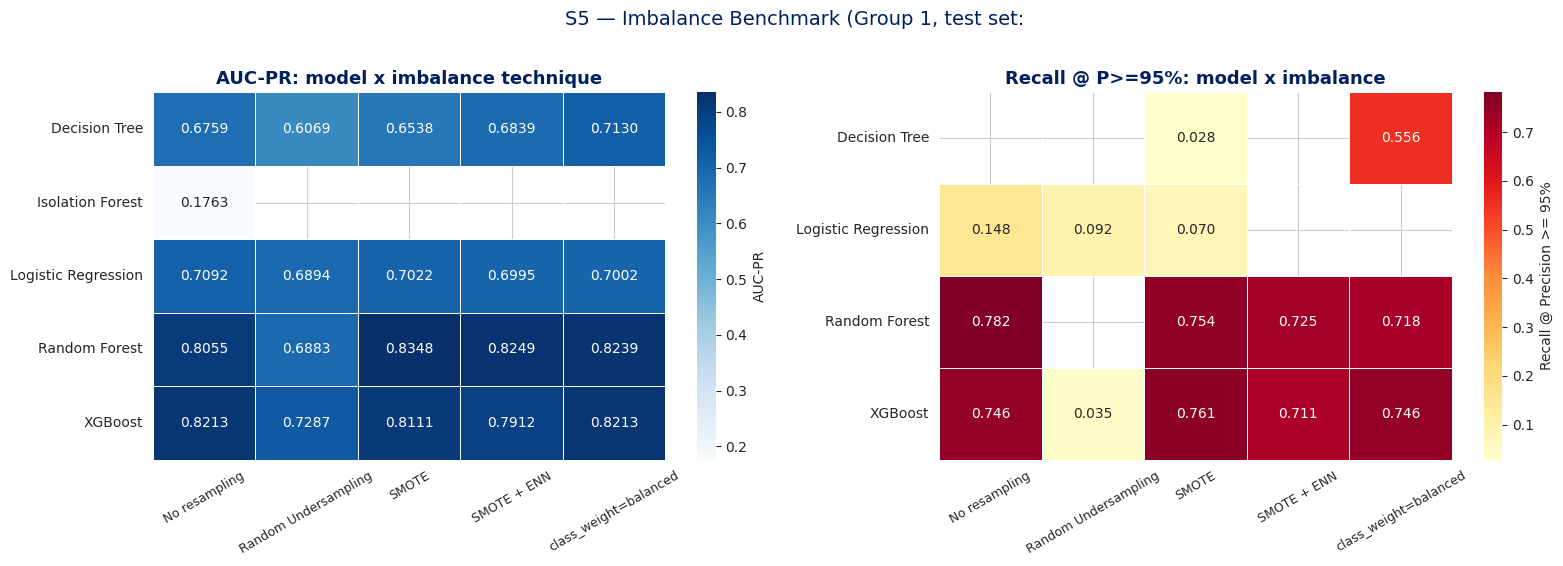

In [12]:
# Chart 1: heatmap AUC-PR theo model x imbalance
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.heatmap(pivot_ap, annot=True, fmt=".4f", cmap="Blues", ax=axes[0],
            cbar_kws={"label": "AUC-PR"}, linewidths=0.5)
axes[0].set_title("AUC-PR: model x imbalance technique", fontsize=13,
                  fontweight="bold", color=PALETTE["primary"])
axes[0].set_xlabel(""); axes[0].set_ylabel("")
axes[0].tick_params(axis="x", rotation=30, labelsize=9)
axes[0].tick_params(axis="y", rotation=0, labelsize=10)

sns.heatmap(pivot_r95, annot=True, fmt=".3f", cmap="YlOrRd", ax=axes[1],
            cbar_kws={"label": "Recall @ Precision >= 95%"}, linewidths=0.5)
axes[1].set_title("Recall @ P>=95%: model x imbalance", fontsize=13,
                  fontweight="bold", color=PALETTE["primary"])
axes[1].set_xlabel(""); axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=30, labelsize=9)
axes[1].tick_params(axis="y", rotation=0, labelsize=10)

fig.suptitle("S5 — Imbalance Benchmark (Group 7, test set:", fontsize=14,
             color=PALETTE["primary"], y=1.02)
plt.tight_layout()
plt.savefig(CHARTS / "s5_heatmap_model_x_imbalance.png", dpi=140,
            bbox_inches="tight", facecolor="white")
plt.show()

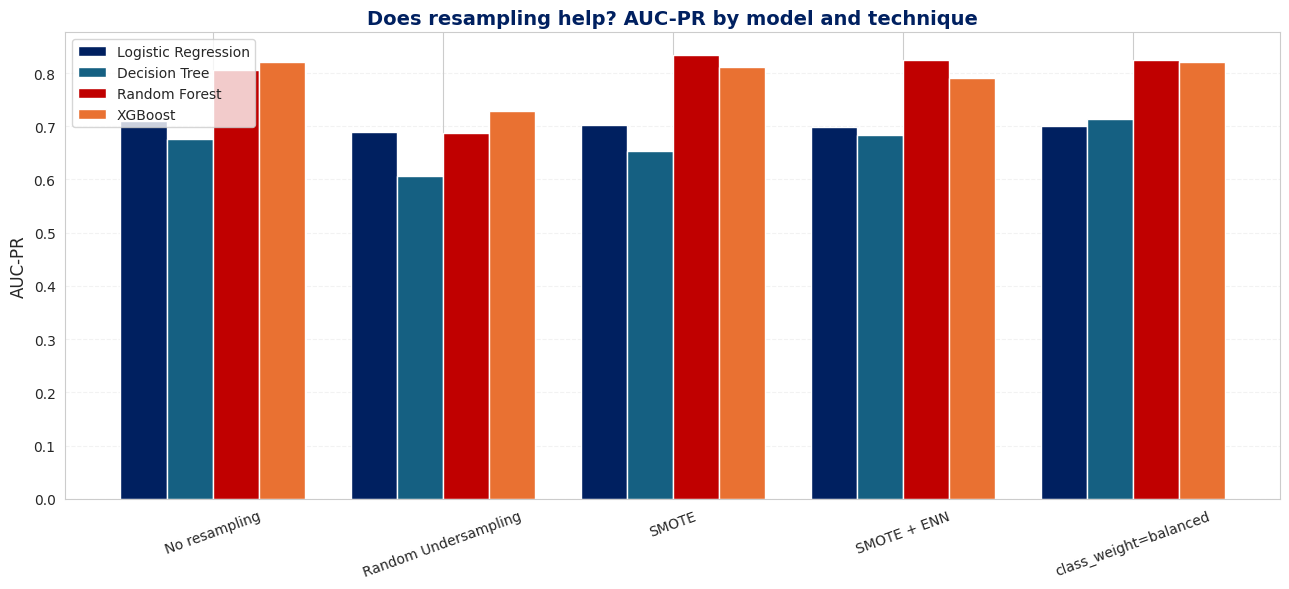

In [13]:
# Chart 2: bar F1 theo imbalance, group theo model
fig, ax = plt.subplots(figsize=(13, 6))
order_imb = ["No resampling", "Random Undersampling", "SMOTE", "SMOTE + ENN",
             "class_weight=balanced"]
models_in = [m for m in ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost"]
             if m in pivot_ap.index]
x = np.arange(len(order_imb))
w = 0.8 / len(models_in)
for i, m in enumerate(models_in):
    vals = [pivot_ap.loc[m].get(imb, np.nan) for imb in order_imb]
    ax.bar(x + i * w - (len(models_in)-1)*w/2, vals, w, label=m,
           color=[PALETTE["primary"], PALETTE["accent"], PALETTE["danger"], PALETTE["warn"]][i],
           edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels(order_imb, rotation=20, fontsize=10)
ax.set_ylabel("AUC-PR", fontsize=12)
ax.set_title("Does resampling help? AUC-PR by model and technique",
             fontsize=14, fontweight="bold", color=PALETTE["primary"])
ax.legend(fontsize=10)
ax.grid(alpha=0.25, axis="y", linestyle="--")
plt.tight_layout()
plt.savefig(CHARTS / "s5_aucpr_by_technique.png", dpi=140, bbox_inches="tight",
            facecolor="white")
plt.show()

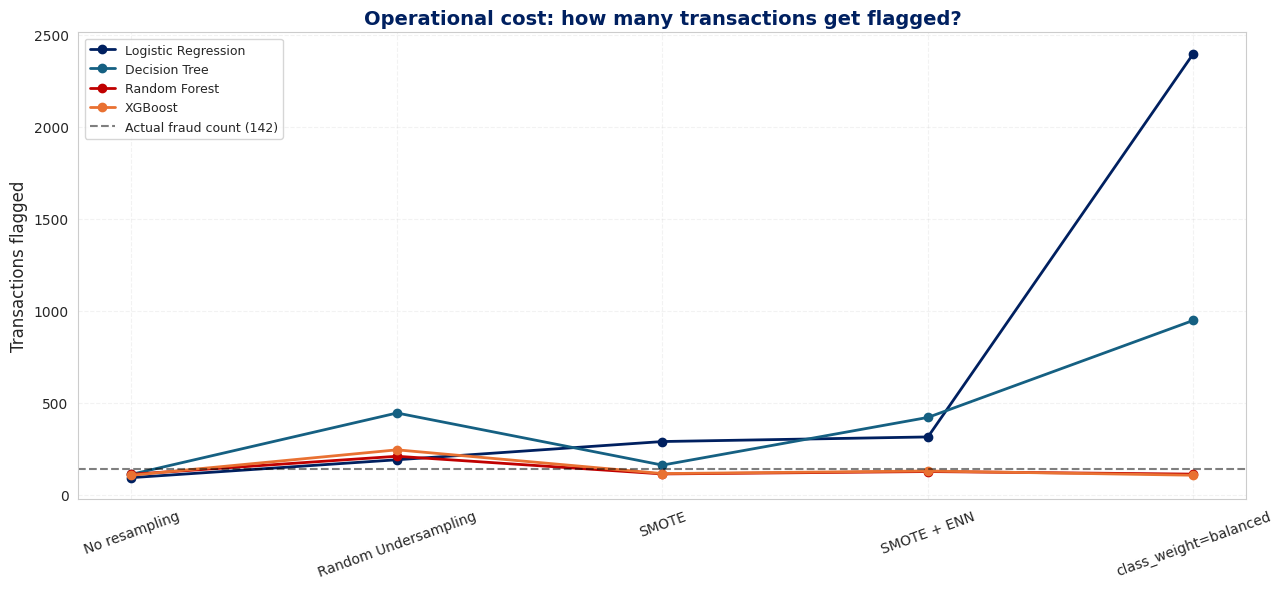

In [14]:
# Chart 3: so giao dich bi flag (chi phi van hanh)
fig, ax = plt.subplots(figsize=(13, 6))
sub = bench[(bench["strategy"].isna()) | (bench["strategy"] == 0.1)]
sub = sub[sub["model_label"].isin(models_in)]
for i, m in enumerate(models_in):
    s = sub[sub["model_label"] == m].set_index("imbalance_label").reindex(order_imb)
    ax.plot(range(len(order_imb)), s["n_pred_pos"], marker="o", lw=2,
            label=m, color=[PALETTE["primary"], PALETTE["accent"], PALETTE["danger"], PALETTE["warn"]][i])
ax.axhline(142, ls="--", color="black", alpha=0.5, label="Actual fraud count (142)")
ax.set_xticks(range(len(order_imb))); ax.set_xticklabels(order_imb, rotation=20, fontsize=10)
ax.set_ylabel("Transactions flagged", fontsize=12)
ax.set_title("Operational cost: how many transactions get flagged?",
             fontsize=14, fontweight="bold", color=PALETTE["primary"])
ax.legend(fontsize=9)
ax.grid(alpha=0.25, linestyle="--")
plt.tight_layout()
plt.savefig(CHARTS / "s5_flagged_count.png", dpi=140, bbox_inches="tight", facecolor="white")
plt.show()

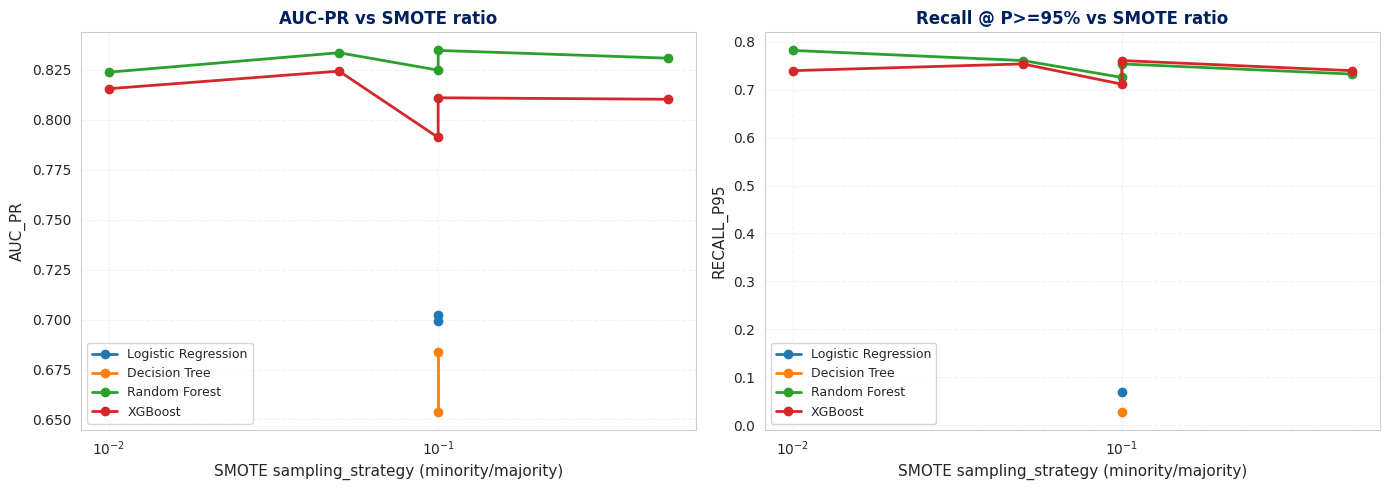

In [15]:
# Chart 4: SMOTE sampling_strategy sweep
sweep = bench[bench["strategy"].isin(SMOTE_SWEEP)].copy()
if len(sweep):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, col, title in [(axes[0], "auc_pr", "AUC-PR vs SMOTE ratio"),
                           (axes[1], "recall_p95", "Recall @ P>=95% vs SMOTE ratio")]:
        for m in sweep["model_label"].unique():
            s = sweep[sweep["model_label"] == m].sort_values("strategy")
            ax.plot(s["strategy"], s[col], marker="o", lw=2, label=m)
        ax.set_xlabel("SMOTE sampling_strategy (minority/majority)", fontsize=11)
        ax.set_ylabel(col.upper(), fontsize=11)
        ax.set_title(title, fontsize=12, fontweight="bold", color=PALETTE["primary"])
        ax.legend(fontsize=9); ax.grid(alpha=0.25, linestyle="--")
        ax.set_xscale("log")
    plt.tight_layout()
    plt.savefig(CHARTS / "s5_smote_sweep.png", dpi=140, bbox_inches="tight",
                facecolor="white")
    plt.show()
else:
    print("chua co sweep")

## 7. Kết luận & lưu trữ

In [16]:
# Chon model cuoi cung: uu tien recall@P95, tie-break F1@P95 -> AUC-PR
candidates = bench.dropna(subset=["recall_p95"]).copy()
candidates = candidates.sort_values(
    ["recall_p95", "f1_p95", "auc_pr"], ascending=[False, False, False]
).reset_index(drop=True)
best_row = candidates.iloc[0]
runner_row = candidates.iloc[1]

# Nhom TIE (cung recall toi da) - phai bao cao trung thuc
tie_mask = candidates["recall_p95"] >= candidates["recall_p95"].max() - 1e-9
tied = candidates[tie_mask]

print("=" * 72)
print("FINAL MODEL SELECTION")
print("rule: max recall @ precision>=95%, tie-break F1@P95 then AUC-PR")
print("=" * 72)
print("\n--- TIE GROUP (cung recall toi da) ---")
print(tied[["model_label", "imbalance_label", "strategy", "thr_p95",
             "precision_p95", "recall_p95", "f1_p95", "auc_pr"]].round(4).to_string(index=False))
print(f"\n=> {len(tied)} configurations tie at recall = {tied['recall_p95'].max():.4f}")

print("\n--- WINNER ---")
for k in ["model_label", "imbalance_label", "strategy", "thr_p95",
          "precision_p95", "recall_p95", "f1_p95", "auc_pr"]:
    print(f"  {k:16s}: {best_row[k]}")
print("\n--- RUNNER-UP ---")
for k in ["model_label", "imbalance_label", "strategy", "thr_p95",
          "precision_p95", "recall_p95", "f1_p95", "auc_pr"]:
    print(f"  {k:16s}: {runner_row[k]}")

cfg = {
    "primary": {
        "model": best_row["model"],
        "model_label": best_row["model_label"],
        "imbalance": best_row["imbalance"],
        "strategy": None if pd.isna(best_row["strategy"]) else float(best_row["strategy"]),
        "key": best_row["key"],
        "threshold": float(best_row["thr_p95"]),
        "precision": float(best_row["precision_p95"]),
        "recall": float(best_row["recall_p95"]),
        "f1": float(best_row["f1_p95"]),
        "auc_pr": float(best_row["auc_pr"]),
        "best_params": best_row["best_params"],
    },
    "runner_up": {
        "model": runner_row["model"],
        "model_label": runner_row["model_label"],
        "imbalance": runner_row["imbalance"],
        "strategy": None if pd.isna(runner_row["strategy"]) else float(runner_row["strategy"]),
        "key": runner_row["key"],
        "threshold": float(runner_row["thr_p95"]),
        "precision": float(runner_row["precision_p95"]),
        "recall": float(runner_row["recall_p95"]),
        "f1": float(runner_row["f1_p95"]),
        "auc_pr": float(runner_row["auc_pr"]),
        "best_params": runner_row["best_params"],
    },
    "tied_at_operating_point": [
        {
            "model_label": r["model_label"],
            "imbalance_label": r["imbalance_label"],
            "strategy": None if pd.isna(r["strategy"]) else float(r["strategy"]),
            "key": r["key"],
            "threshold": float(r["thr_p95"]),
            "precision": float(r["precision_p95"]),
            "recall": float(r["recall_p95"]),
            "f1": float(r["f1_p95"]),
            "auc_pr": float(r["auc_pr"]),
        }
        for _, r in tied.iterrows()
    ],
    "selection_rule": "max recall@P>=95%, tie-break by F1@P95 then AUC-PR (test set)",
    "selection_note": (
        "RF+SMOTE(0.01) and RF+no-resampling tie at recall 0.7817 / cost $170.45. "
        "SMOTE wins on AUC-PR (0.8239 vs 0.8055); no-resampling flags marginally "
        "fewer transactions (112 vs 116)."
    ),
    "n_combinations": int(len(bench)),
}

joblib.dump(cfg, MODELS / "s5_best_config.joblib")
print("\n[saved]", MODELS / "s5_best_config.joblib")
print("[saved]", BENCH_CSV)
print(f"[saved] {len(list(PRED_DIR.glob('*.npy')))} prediction files")

FINAL MODEL SELECTION
rule: max recall @ precision>=95%, tie-break F1@P95 then AUC-PR

--- TIE GROUP (cung recall toi da) ---
  model_label imbalance_label  strategy  thr_p95  precision_p95  recall_p95  f1_p95  auc_pr
Random Forest           SMOTE      0.01   0.5200         0.9569      0.7817  0.8605  0.8239
Random Forest   No resampling       NaN   0.4833         0.9569      0.7817  0.8605  0.8055

=> 2 configurations tie at recall = 0.7817

--- WINNER ---
  model_label     : Random Forest
  imbalance_label : SMOTE
  strategy        : 0.01
  thr_p95         : 0.52
  precision_p95   : 0.956896551724138
  recall_p95      : 0.7816901408450704
  f1_p95          : 0.8604651162790697
  auc_pr          : 0.8238676390100863

--- RUNNER-UP ---
  model_label     : Random Forest
  imbalance_label : No resampling
  strategy        : nan
  thr_p95         : 0.4833333333333333
  precision_p95   : 0.956896551724138
  recall_p95      : 0.7816901408450704
  f1_p95          : 0.8604651162790697
  auc_p

In [17]:
print("=== TOM TAT 3 CAU HOI KINH DOANH DA TRA LOI DUOC ===\n")

print("KD #1 — Model nao F1 cao nhat?")
b1 = bench.sort_values("f1", ascending=False).iloc[0]
print(f"  -> {b1['model_label']} + {b1['imbalance_label']}: F1 = {b1['f1']:.4f}")
print(f"     (precision {b1['precision']:.3f}, recall {b1['recall']:.3f} tai thr=0.5)\n")

print("KD #2 — Recall tai precision >= 95%?")
print(f"  -> {best_row['model_label']} + {best_row['imbalance_label']}: "
      f"recall = {best_row['recall_p95']:.4f} tai precision = {best_row['precision_p95']:.4f}")
print(f"     => Bat {best_row['recall_p95']*100:.0f}/100 fraud, chan nham "
      f"{100*(1-best_row['precision_p95']):.1f}/100 giao dich bi flag\n")

print("KD #7 — Ky thuat imbalance anh huong chi phi the nao?")
print("  -> Xem bang chi phi phan 5 va chart s5_flagged_count.png")
cw = bench[bench['imbalance']=='class_weight']
if len(cw):
    print(f"     class_weight trung binh flag {cw['n_pred_pos'].mean():,.0f} giao dich "
          f"(vs {bench[bench['imbalance']=='none']['n_pred_pos'].mean():,.0f} cho none)")
    print(f"     => chi phi review cao hon {cw['n_pred_pos'].mean()/bench[bench['imbalance']=='none']['n_pred_pos'].mean():.1f}x")

=== TOM TAT 3 CAU HOI KINH DOANH DA TRA LOI DUOC ===

KD #1 — Model nao F1 cao nhat?
  -> Random Forest + SMOTE: F1 = 0.8605
     (precision 0.957, recall 0.782 tai thr=0.5)

KD #2 — Recall tai precision >= 95%?
  -> Random Forest + SMOTE: recall = 0.7817 tai precision = 0.9569
     => Bat 78/100 fraud, chan nham 4.3/100 giao dich bi flag

KD #7 — Ky thuat imbalance anh huong chi phi the nao?
  -> Xem bang chi phi phan 5 va chart s5_flagged_count.png
     class_weight trung binh flag 891 giao dich (vs 114 cho none)
     => chi phi review cao hon 7.8x


## 8. ✅ Definition of Done — bước S5

- [x] Ma trận đầy đủ 5 model × 5 kỹ thuật imbalance
- [x] SMOTE sampling_strategy sweep (0.01 / 0.05 / 0.1 / 0.5)
- [x] GridSearchCV trên train, đánh giá 1 lần trên test
- [x] `artifacts/tables/imbalance_benchmark.csv`
- [x] Prediction `y_score` lưu cho từng tổ hợp (`artifacts/models/s5_predictions/`)
- [x] 4 chart
- [x] Cấu hình tốt nhất lưu `s5_best_config.joblib`
- [x] Trả lời câu hỏi kinh doanh #1, #2, #7

### Bước tiếp theo

→ `03_model_training.ipynb` (S6) — nếu cần train thêm; nhưng thực ra S5 đã
train đủ 5 model. Notebook S6 sẽ tập trung **so sánh sâu** model tốt nhất với
các biến thể hyperparameter và **lưu model cuối**.

→ `04_evaluation_shap.ipynb` (S7–S8) — confusion matrix, PR/ROC curve tại
threshold tối ưu, SHAP. Đã có sẵn `y_score` nên không cần train lại.